In [18]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from urllib.parse import quote_plus
from sqlalchemy import create_engine

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_score

pio.templates.default = "plotly_white"

<div dir="rtl" style="text-align: right;">

### ۱. خواندن و آماده‌سازی داده‌ها

داده‌ها از دیتابیس MySQL با نام `basketball` و با کوئری SQL خوانده می‌شوند. هر جدول دیتابیس به یک DataFrame تبدیل می‌شود و ستون‌ها همان نام ستون‌های جدول‌های SQL را دارند (مثل `points_per_game` و `full_name`). ستون‌های `season_end`، `team_name_abbr`، `minutes_per_game` و `ranker` از روی داده‌های دیتابیس ساخته می‌شوند. بازهٔ تحلیل فصل‌های ۲۰۱۹-۲۰ تا ۲۰۲۳-۲۴ است (`season_end` از ۲۰۲۰ تا ۲۰۲۴).

</div>

In [19]:


DB_USER = "sql12839537"
DB_PASSWORD = 'AWXXSAVcT3'
DB_HOST = "sql12.freesqldatabase.com"
DB_PORT = 3306
DB_NAME = "sql12839537"

engine = create_engine(
    f"mysql+pymysql://{DB_USER}:{quote_plus(DB_PASSWORD)}@{DB_HOST}:{DB_PORT}/{DB_NAME}?charset=utf8mb4"
)


def q(sql):
    return pd.read_sql(sql, engine)

In [20]:
FIRST_SEASON_END, LAST_SEASON_END = 2020, 2024


stints = q(f"""
    SELECT p.player_id, s.start_year + 1 AS season_end, t.team_code AS team_name_abbr,
           pos.position_name, p.age, p.games_played, p.games_started, p.minutes_played,
           p.points_per_game, p.rebounds_per_game, p.assists_per_game, p.steals_per_game,
           p.blocks_per_game, p.three_point_attempts_per_game, p.field_goal_attempts_per_game,
           p.field_goal_percentage
    FROM player_season_stats p
    JOIN seasons s ON s.season_id = p.season_id
    JOIN teams t ON t.team_id = p.team_id
    LEFT JOIN positions pos ON pos.position_id = p.position_id
    WHERE s.start_year + 1 BETWEEN {FIRST_SEASON_END} AND {LAST_SEASON_END}
""")


stints["team_name_abbr"] = stints.team_name_abbr.replace({"NJN": "BRK", "NOH": "NOP", "CHA": "CHO"})
stints["minutes_per_game"] = (stints.minutes_played / stints.games_played).round(1)


rate_cols = ["points_per_game", "rebounds_per_game", "assists_per_game", "steals_per_game", "blocks_per_game",
             "three_point_attempts_per_game", "field_goal_attempts_per_game", "field_goal_percentage", "minutes_per_game"]

traded = stints[stints.duplicated(["player_id", "season_end"], keep=False)].copy()
traded[rate_cols] = traded[rate_cols].mul(traded.games_played, axis=0)   
total = traded.groupby(["player_id", "season_end"]).agg(
    {**{c: "sum" for c in rate_cols + ["games_played", "games_started"]},
     "position_name": "first", "age": "first", "team_name_abbr": "count"}).reset_index()
total[rate_cols] = total[rate_cols].div(total.games_played, axis=0).round(3)
total["team_name_abbr"] = total.team_name_abbr.astype(str) + "TM"

pg = pd.concat([stints, total], ignore_index=True)


MIN_GP = 40   

season = pg.sort_values("games_played", ascending=False).drop_duplicates(["player_id", "season_end"]).copy()
eligible = season[season.games_played >= MIN_GP]
season["ranker"] = (eligible.groupby("season_end").points_per_game
                    .rank(method="min", ascending=False))         
season["ranker"] = season["ranker"].astype("Int64")              
pg = pg.merge(season[["player_id", "season_end", "ranker"]],
              on=["player_id", "season_end"], how="left")         

adv = q(f"SELECT * FROM player_advanced_stats WHERE season_end BETWEEN {FIRST_SEASON_END} AND {LAST_SEASON_END}")
adv = adv.merge(pg[["player_id", "season_end", "team_name_abbr", "position_name", "games_played", "games_started"]],
                on=["player_id", "season_end", "team_name_abbr"], how="left")

In [21]:
info = q("SELECT * FROM players")
league = q("SELECT * FROM league_stats")
teams = q("SELECT * FROM teams")


seasons = q("""
    SELECT s.start_year, pl.full_name
    FROM seasons s LEFT JOIN players pl ON pl.player_id = s.mvp_player_id
    ORDER BY s.start_year
""")


mvp = q(f"""
    SELECT s.start_year + 1 AS season_end, p.player_id, pl.full_name, p.mvp_rank, p.mvp_points
    FROM player_season_stats p
    JOIN seasons s ON s.season_id = p.season_id
    JOIN players pl ON pl.player_id = p.player_id
    WHERE p.is_mvp_candidate = 1
      AND s.start_year + 1 BETWEEN {FIRST_SEASON_END} AND {LAST_SEASON_END}
""")
mvp = mvp.sort_values(["season_end", "mvp_rank"]).drop_duplicates(["season_end", "player_id"])

champ_players = q(f"""
    SELECT s.start_year + 1 AS season_end, p.player_id, p.team_id, p.age, p.games_played, p.experience
    FROM player_season_stats p
    JOIN seasons s ON s.season_id = p.season_id
    JOIN team_stats ts ON ts.team_id = p.team_id AND ts.season_id = p.season_id
    WHERE ts.is_champion = 1
      AND s.start_year + 1 BETWEEN {FIRST_SEASON_END} AND {LAST_SEASON_END}
""")

In [22]:
def fix(s):
    try:
        return s.encode("latin-1").decode("utf-8")
    except Exception:
        return s

In [23]:
league = league[(league.season_type == "Regular-Season") & (league.stat_mode == "per_game")]
league = league.dropna(subset=["points_per_game"]).copy()
league["year"] = league.season.str[:4].astype(int) + 1
league = league.sort_values("year")


league.describe()

,source_row,points_per_game,three_point_attempts_per_game,field_goal_attempts_per_game,year
count,89.000000,89.000000,56.000000,89.000000,89.000000
mean,87.651685,104.114607,14.782143,89.598876,1985.033708
std,137.160250,10.556434,10.749632,7.803911,22.467375
min,3.000000,67.800000,2.000000,75.400000,1947.000000
25%,25.000000,99.000000,5.225000,83.000000,1968.000000
50%,47.000000,106.600000,14.200000,88.800000,1982.000000
75%,69.000000,111.200000,18.800000,95.300000,2004.000000
max,493.000000,118.800000,37.600000,109.400000,2026.000000


In [24]:
adv_cols = ["minutes_played", "played_efficiency_rating", "true_shooting_percentage", "three_point_attempt_rate", "free_throw_attempt_rate", "offensive_rebound_percentage", "defensive_rebound_percentage",
            "total_rebound_percentage", "assist_percentage", "steal_percentage", "block_percentage", "turnover_percentage", "usage_percentage", "offensive_win_shares", "defensive_win_shares", "win_shares",
            "win_shares_per_48_minutes", "offensive_box_plus_minus", "defensive_box_plus_minus", "box_plus_minus", "value_over_replacement_player"]
for c in adv_cols:
    adv[c] = pd.to_numeric(adv[c].astype(str).str.replace("'", "", regex=False), errors="coerce")


cols = ["player_id", "season_end", "team_name_abbr", "points_per_game", "rebounds_per_game", "assists_per_game",
        "steals_per_game", "blocks_per_game", "three_point_attempts_per_game",
        "minutes_per_game", "field_goal_percentage"]
players = adv.merge(pg[cols], on=["player_id", "season_end", "team_name_abbr"])
players["name"] = players.name_display.map(fix)


players = players.sort_values("minutes_played", ascending=False).drop_duplicates(["player_id", "season_end"])

In [25]:
players.describe()

,source_row,season_end,age,minutes_played,played_efficiency_rating,true_shooting_percentage,three_point_attempt_rate,free_throw_attempt_rate,offensive_rebound_percentage,defensive_rebound_percentage,...,games_played,games_started,points_per_game,rebounds_per_game,assists_per_game,steals_per_game,blocks_per_game,three_point_attempts_per_game,minutes_per_game,field_goal_percentage
count,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2768.000000,2767.000000,2767.000000,2785.000000,2785.000000,...,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2785.000000,2767.000000
mean,1780.198923,2022.030521,25.671095,1011.086894,12.894399,0.545243,0.396860,0.248145,5.136409,15.006248,...,44.445242,20.929982,8.676141,3.520900,1.966176,0.607427,0.391413,2.722566,19.319263,0.449159
std,1046.013492,1.403045,4.171035,786.472991,6.730456,0.108734,0.219597,0.191573,4.811591,6.813242,...,24.102108,25.563501,6.568568,2.411124,1.855140,0.399658,0.398825,2.249169,9.562933,0.113105
min,2.000000,2020.000000,19.000000,1.000000,-45.200000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
25%,850.000000,2021.000000,23.000000,261.000000,9.800000,0.511000,0.259500,0.141500,2.000000,10.600000,...,23.000000,0.000000,3.800000,1.800000,0.700000,0.300000,0.100000,0.904000,11.600000,0.403000
50%,1775.000000,2022.000000,25.000000,915.000000,12.800000,0.558000,0.406000,0.224000,3.600000,13.700000,...,50.000000,7.000000,6.900000,3.100000,1.300000,0.600000,0.300000,2.262000,18.811000,0.447000
75%,2706.000000,2023.000000,28.000000,1682.000000,16.300000,0.599000,0.540000,0.315000,7.000000,18.700000,...,65.000000,39.000000,11.800000,4.600000,2.600000,0.897000,0.500000,4.094000,27.600000,0.499500
max,3583.000000,2024.000000,43.000000,2989.000000,76.200000,1.078000,1.000000,3.000000,80.900000,74.700000,...,84.000000,83.000000,34.700000,15.140000,11.700000,3.000000,3.600000,12.700000,43.500000,1.000000


<div dir="rtl" style="text-align: right;">

### ۲. رسم نمودارها

</div>

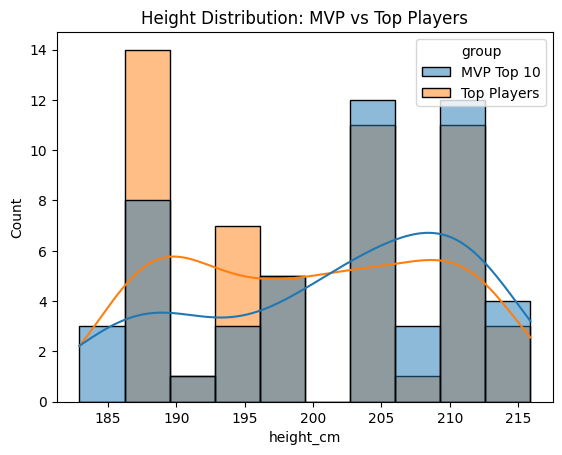

In [26]:
top_mvp = mvp[mvp.mvp_rank <= 10][["season_end", "player_id"]].assign(group="MVP Top 10")
top_pts = pg[pg.ranker <= 10][["season_end", "player_id"]].drop_duplicates().assign(group="Top Players")
heights = pd.concat([top_mvp, top_pts]).merge(info[["player_id", "height_cm"]], on="player_id", how="left")

sns.histplot(data=heights, x="height_cm", hue="group", bins=10, alpha=0.5, kde=True)
plt.title("Height Distribution: MVP vs Top Players")
plt.show()

In [27]:
pg.describe()

,season_end,age,games_played,games_started,minutes_played,points_per_game,rebounds_per_game,assists_per_game,steals_per_game,blocks_per_game,three_point_attempts_per_game,field_goal_attempts_per_game,field_goal_percentage,minutes_per_game,ranker
count,3582.000000,3582.000000,3582.000000,3582.000000,3198.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3582.000000,3552.000000,3582.000000,2175.0
mean,2022.039643,25.980458,39.224456,17.889447,880.511882,8.329021,3.426607,1.901759,0.597539,0.381319,2.660231,6.690036,0.445499,18.887367,177.728736
std,1.390354,4.176791,24.338782,23.916102,769.965385,6.350579,2.356349,1.812448,0.403600,0.389725,2.200702,4.726522,0.118495,9.433242,98.249701
min,2020.000000,19.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,1.0
25%,2021.000000,23.000000,17.000000,0.000000,176.000000,3.700000,1.726000,0.700000,0.300000,0.100000,0.900000,3.200000,0.399000,11.500000,94.0
50%,2022.000000,25.000000,40.000000,5.000000,675.000000,6.700000,3.000000,1.300000,0.531000,0.300000,2.200000,5.500000,0.444000,18.200000,179.0
75%,2023.000000,29.000000,61.000000,29.000000,1478.750000,11.300000,4.500000,2.500000,0.809500,0.500000,3.939500,9.100000,0.500000,26.700000,262.0
max,2024.000000,43.000000,84.000000,83.000000,2989.000000,34.700000,15.800000,11.700000,3.000000,3.600000,12.700000,23.600000,1.000000,43.500000,356.0


<div dir="rtl" style="text-align: right;">

### معرفی ستون‌ها

- **`season_end` — سال پایان فصل:** سالی که فصل مسابقات NBA در آن به پایان رسیده است.

- **`points_per_game` — میانگین امتیاز در هر بازی:** میانگین تعداد امتیازهایی که بازیکن در هر مسابقه کسب کرده است.

- **`rebounds_per_game` — میانگین ریباند در هر بازی:** میانگین تعداد ریباندهای کل بازیکن در هر مسابقه؛ شامل ریباندهای دفاعی و هجومی.

- **`assists_per_game` — میانگین پاس گل در هر بازی:** میانگین تعداد پاس‌های منجر به امتیاز بازیکن در هر مسابقه.

</div>

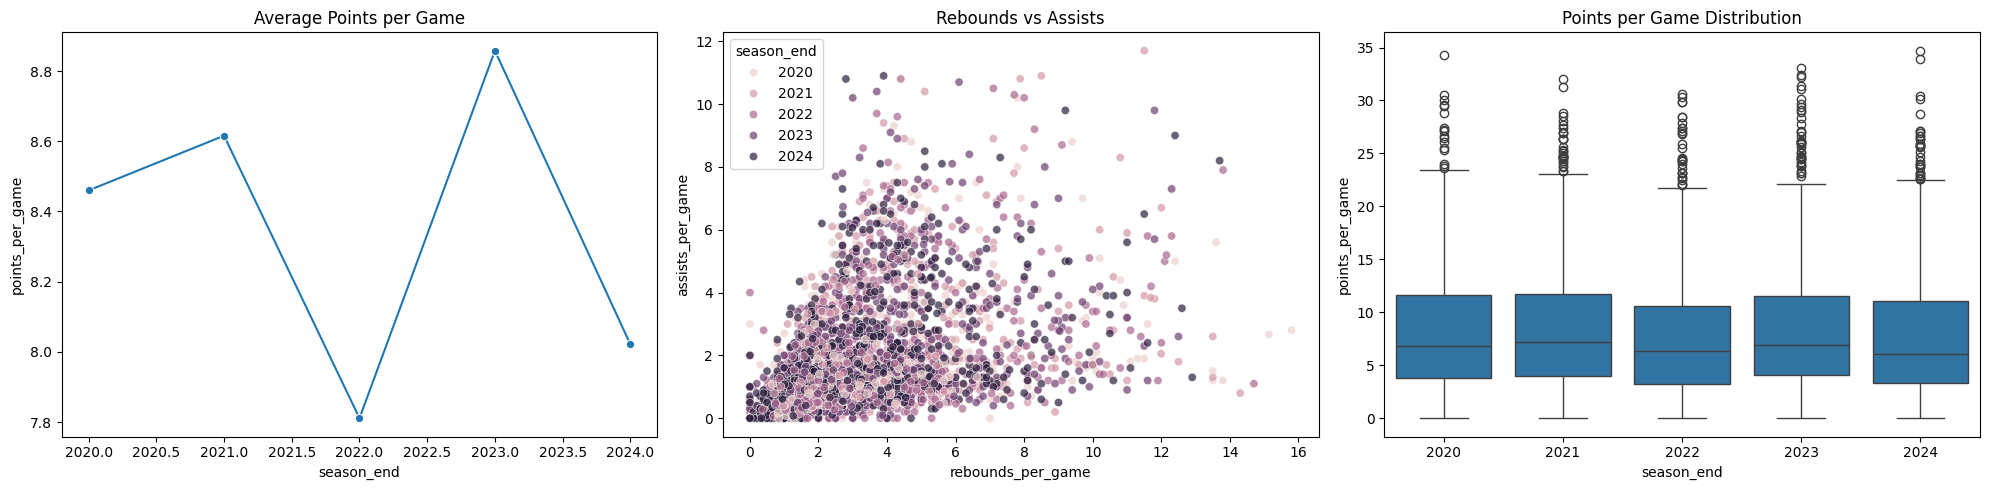

In [28]:
d = pg[["season_end", "points_per_game", "rebounds_per_game", "assists_per_game"]].dropna()

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.lineplot(data=d, x="season_end", y="points_per_game", errorbar=None, marker="o", ax=ax[0])
sns.scatterplot(data=d, x="rebounds_per_game", y="assists_per_game", hue="season_end", alpha=0.7, ax=ax[1])
sns.boxplot(data=d, x="season_end", y="points_per_game", ax=ax[2])
ax[0].set_title("Average Points per Game")
ax[1].set_title("Rebounds vs Assists")
ax[2].set_title("Points per Game Distribution")
plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">

### معرفی ستون‌ها

- **`three_point_attempts_per_game` — میانگین تلاش برای پرتاب سه‌امتیازی در هر بازی:** میانگین تعداد دفعاتی که بازیکن در هر مسابقه برای شوت سه‌امتیازی تلاش کرده است؛ چه شوت موفق باشد و چه ناموفق.

- **`field_goal_attempts_per_game` — میانگین تعداد کل تلاش‌های شوت‌زنی در هر بازی:** میانگین تعداد دفعاتی که بازیکن برای شوت‌های دو‌امتیازی و سه‌امتیازی تلاش کرده است؛ شامل شوت‌های موفق و ناموفق، بدون احتساب پرتاب‌های آزاد.

</div>

In [29]:
l3 = league[league.year >= 1980]
share = l3.three_point_attempts_per_game / l3.field_goal_attempts_per_game * 100

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=l3.year, y=l3.three_point_attempts_per_game, name="3PA per game")
fig.add_scatter(x=l3.year, y=share, name="3PA share (%)", mode="lines+markers", secondary_y=True)
fig.update_layout(title="The 3-Point Revolution", height=500)
fig.show(renderer="plotly_mimetype")

<div dir="rtl" style="text-align: right;">

### تحلیل روند استفاده از پرتاب‌های سه‌امتیازی در NBA

- **نسبت پرتاب‌های سه‌امتیازی به کل شوت‌ها:** نشان می‌دهد چه درصدی از تمام تلاش‌های شوت‌زنی بازیکنان از فاصلهٔ سه‌امتیازی انجام شده است؛ شامل شوت‌های موفق و ناموفق.
- **تغییرات تاریخی:** نمودار افزایش تدریجی سهم پرتاب‌های سه‌امتیازی را در طول فصل‌های NBA نشان می‌دهد. جهش قابل‌توجه در میانهٔ دههٔ ۱۹۹۰ با کوتاه‌شدن موقت فاصلهٔ خط سه‌امتیازی مرتبط است.
- **روند سال‌های اخیر:** افزایش این نسبت نشان می‌دهد که تیم‌ها به‌مرور سهم بیشتری از شوت‌های خود را به پرتاب‌های سه‌امتیازی اختصاص داده‌اند.

**منبع برای مطالعهٔ بیشتر:** [مقالهٔ NBA دربارهٔ تحول پرتاب‌های سه‌امتیازی](https://www.nba.com/news/3-point-era-nba-75)

</div>

In [30]:
from IPython.display import HTML, display

gif_url = "https://cdn.nba.com/manage/2021/10/01_League3Ptrend_small.gif"

display(HTML(f'<img src="{gif_url}" width="500">'))

<div dir="rtl" style="text-align: right;">

### معرفی ستون‌ها

- **`usage_percentage` — درصد استفاده از مالکیت توپ:** نشان می‌دهد چه درصدی از مالکیت‌های تیم هنگام حضور بازیکن در زمین، با اقدام او برای شوت‌زدن، از دست دادن توپ یا گرفتن پرتاب آزاد به پایان می‌رسد. این شاخص میزان مشارکت بازیکن در حمله را نشان می‌دهد.

- **`true_shooting_percentage` — درصد شوت‌زنی واقعی:** معیاری برای سنجش کارایی امتیازگیری بازیکن است که شوت‌های دو‌امتیازی، سه‌امتیازی و پرتاب‌های آزاد را در نظر می‌گیرد.

- **`box_plus_minus` — امتیاز تأثیر بازیکن:** تخمینی از تأثیر کلی بازیکن بر عملکرد تیم، به ازای هر ۱۰۰ مالکیت توپ و در مقایسه با میانگین لیگ است. مقدار مثبت معمولاً نشان‌دهنده تأثیر بهتر از میانگین لیگ است.

- **`value_over_replacement_player` — ارزش بازیکن نسبت به بازیکن جایگزین:** تخمین می‌زند بازیکن در مقایسه با یک بازیکن جایگزین در سطح پایین‌تر، چه میزان ارزش اضافی برای تیم ایجاد می‌کند. مقدار بالاتر معمولاً نشان‌دهنده ارزش بیشتر است.

- **`win_shares` — بردهای کسب‌شده:** تخمینی از سهم بازیکن در پیروزی‌های تیم است که عملکرد تهاجمی و دفاعی او را در نظر می‌گیرد.

- **`minutes_played` — مجموع دقایق بازی:** تعداد کل دقایقی که بازیکن در طول فصل در زمین حضور داشته است.

</div>

In [31]:
d = players[players.minutes_played >= 1500].dropna(subset=["usage_percentage", "true_shooting_percentage", "box_plus_minus", "value_over_replacement_player", "win_shares"]).copy()
d["size"] = d.win_shares.clip(lower=0.5)

fig = px.scatter_3d(d, x="usage_percentage", y="true_shooting_percentage", z="box_plus_minus", color="value_over_replacement_player", size="size",
                    size_max=16, hover_name="name", opacity=0.8, color_continuous_scale="Turbo")
fig.update_layout(title="Player Impact (size = Win Shares, color = VORP)", height=550,width=650)
fig.show()

In [32]:
age = players[(players.minutes_played >= 500) & players.age.between(19, 37)]

bpm_mean = age.groupby("age")["box_plus_minus"].mean()

player_count = age.groupby("age")["box_plus_minus"].count()

age = pd.DataFrame({
    "age": bpm_mean.index,
    "box_plus_minus": bpm_mean.values,
    "n": player_count.values
}).reset_index(drop=True)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=age.age, y=age.n, name="Number of players")
fig.add_scatter(x=age.age, y=age.box_plus_minus, name="Mean BPM", mode="lines+markers", secondary_y=True)
fig.update_layout(title="Aging Curve", height=400,width=1000)
fig.show()

In [33]:
seasons["full_name"] = seasons.full_name.map(fix)
top = seasons.full_name.value_counts().head(15).reset_index()
top.columns = ["player", "mvps"]

fig = px.bar(
    top,
    x="player",
    y="mvps",
    text="mvps",
    title="MVP Awards (2015-16 to 2025-26)",
    width=800,
    height=500
)

fig.update_traces(width=0.5)

fig.update_layout(
    xaxis=dict(tickangle=-45),
    xaxis_title="Player",
    yaxis_title="Number of MVP Awards"
)

fig.show()

<div dir="rtl" style="text-align: right;">

### معرفی ستون‌ها

- **`team_name` — نام تیم:** نام تیم یا فرنچایز NBA را مشخص می‌کند که برای شناسایی و مقایسه تیم‌ها در نمودار استفاده می‌شود.

- **`historical_games` — تعداد بازی‌ها:** تعداد بازی‌های ثبت‌شده برای فرنچایز را نشان می‌دهد. در این کد فقط فرنچایزهایی با حداقل ۱۵۰۰ بازی انتخاب شده‌اند.

- **`historical_win_loss_pct` — درصد برد:** نسبت بردهای تیم به کل بازی‌های آن را نشان می‌دهد. مقدار بالاتر به معنای درصد موفقیت بیشتر در بازی‌هاست.

- **`historical_wins` — تعداد بردها:** مجموع بردهای ثبت‌شده برای فرنچایز را نشان می‌دهد.

- **`years_playoffs` — سال‌های حضور در پلی‌آف:** تعداد سال‌هایی را نشان می‌دهد که فرنچایز در مرحله پلی‌آف حضور داشته است. در نمودار، این شاخص برای تعیین اندازه حباب‌ها استفاده می‌شود.

- **`years_league_champion` — سال‌های قهرمانی لیگ:** تعداد سال‌هایی را نشان می‌دهد که فرنچایز قهرمان لیگ شده است. این شاخص رنگ حباب‌ها را تعیین می‌کند.

- **`size` — اندازه حباب:** یک ستون محاسباتی است که از جمع `years_playoffs + 2` ساخته شده تا اندازه حباب‌ها بر اساس سابقه حضور در پلی‌آف تعیین شود و حباب‌ها اندازه صفر نداشته باشند.

</div>

In [34]:
teams = teams[teams.team_name.notna() & (teams.historical_games >= 1500)].copy()
teams["size"] = teams.years_playoffs + 2

fig = px.scatter(teams, x="historical_win_loss_pct", y="historical_wins", size="size", color="years_league_champion",
                 text="team_name", size_max=45, color_continuous_scale="YlOrRd")
fig.update_traces(textposition="top center", textfont_size=9)
fig.update_layout(title="Franchises: Wins vs Win % (size = playoff appearances)", height=650)
fig.show()

In [35]:
cols = ["box_plus_minus", "played_efficiency_rating", "win_shares_per_48_minutes", "value_over_replacement_player", "usage_percentage", "true_shooting_percentage", "assist_percentage", "total_rebound_percentage", "turnover_percentage", "points_per_game"]
corr = players[players.minutes_played >= 500][cols].corr().round(2)


corr = corr.mask(np.triu(np.ones(corr.shape, dtype=bool)))

px.imshow(corr, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
          title="Which stats move together? (players with 500+ minutes, 2019-20 to 2023-24)",
          height=650, width=750).show()

In [36]:
top = (players[players.minutes_played >= 1000]
       .sort_values("box_plus_minus", ascending=False)
       .groupby("season_end").head(5))

fig = px.bar(top, x="season_end", y="box_plus_minus", color="name", text="name",
             title="Top 5 most impactful players each season (by BPM)",
             labels={"season_end": "Season end", "box_plus_minus": "BPM"}, height=600)
fig.update_traces(textposition="inside", textfont_size=10)
fig.update_layout(barmode="group", showlegend=False)
fig.show()

In [37]:
required_cols = ["position_name", "true_shooting_percentage", "minutes_played"]

if all(col in players.columns for col in required_cols):

    position_data = players[required_cols + (
        ["name"] if "name" in players.columns else []
    )].copy()

    position_data = position_data[position_data["minutes_played"] >= 500]

    position_order = (
        position_data.groupby("position_name")["true_shooting_percentage"]
        .median()
        .sort_values()
        .index.tolist()
    )

    fig = px.violin(
        position_data,
        x="position_name",
        y="true_shooting_percentage",
        color="position_name",
        category_orders={"position_name": position_order},
        box=True,
        points="outliers",
        hover_name="name" if "name" in position_data.columns else None,
        hover_data={"minutes_played": True},
        title="NBA Shooting Efficiency by Player Position",
        labels={
            "position_name": "Player Position",
            "true_shooting_percentage": "True Shooting Percentage",
            "minutes_played": "Minutes Played"
        }
    )

    fig.update_layout(
        template="plotly_white",
        title_x=0.5,
        height=600,
        showlegend=False
    )

    fig.show()

else:
    print("Chart skipped: required columns are missing.")

In [38]:
query = """
    SELECT
        t.team_name,
        s.start_year + 1 AS season_end,
        SUM(p.total_points) AS total_points
    FROM player_season_stats p
    JOIN teams t ON p.team_id = t.team_id
    JOIN seasons s ON p.season_id = s.season_id
    GROUP BY t.team_name, s.start_year
    ORDER BY t.team_name, s.start_year
"""

team_points = q(query)
team_points["team_name"] = team_points["team_name"].map(fix)

In [64]:
pivot = team_points.pivot(index="team_name", columns="season_end", values="total_points")

fig = px.imshow(
    pivot,
    labels={"x": "season", "y": "team", "color": "total score in season"},
    color_continuous_scale="reds",
    aspect="auto",
    title="total team score in each season",
    text_auto=".0f",
)

fig.update_layout(
    title_x=0.5,
    height=900,
    xaxis=dict(side="top", tickmode="linear"),
    coloraxis_colorbar=dict(title="امتیاز"),
    paper_bgcolor="#F5F7FA",
    plot_bgcolor="#FFFFFF",
)

fig.update_traces(textfont=dict(size=9))
fig.show()

<div dir="rtl" style="text-align: right;">

### ۳. آزمون فرضیه‌ها

</div>

<div dir="rtl" style="text-align: right;">

### فرضیه اول: بررسی تغییر BMI بازیکنان برتر NBA در طول زمان

**هدف آزمون**

بررسی این ادعا که میانگین شاخص توده بدنی (BMI) در میان ۲۰ بازیکن برتر هر فصل NBA، در دو فصل اخیر نسبت به دو فصل قدیمی‌تر افزایش یافته است.

**تعریف متغیرها**

- **۲۰ بازیکن برتر هر فصل:** بر اساس ستون `ranker` (رتبه بر اساس میانگین امتیاز در هر بازی) انتخاب می‌شوند.
- **شاخص توده بدنی (`BMI`):** از تقسیم وزن بر مجذور قد بر حسب متر محاسبه می‌شود و برای مقایسه وضعیت بدنی بازیکنان به کار می‌رود.
- **گروه قدیم:** فصل‌های ۲۰۲۰–۲۱ و ۲۰۲۱–۲۲، با مقادیر `season_end` برابر ۲۰۲۱ و ۲۰۲۲.
- **گروه جدید:** فصل‌های ۲۰۲۲–۲۳ و ۲۰۲۳–۲۴، با مقادیر `season_end` برابر ۲۰۲۳ و ۲۰۲۴.

در هر گروه، در صورت انتخاب ۲۰ بازیکن در هر فصل، ۴۰ مشاهده بازیکن-فصل خواهیم داشت.

**فرضیه‌های آماری**

- $H_0$: میانگین BMI گروه جدید کمتر یا مساوی گروه قدیم است.
- $H_1$: میانگین BMI گروه جدید بیشتر از گروه قدیم است.

این آزمون یک‌طرفه است و هدف آن بررسی وجود شواهد آماری برای افزایش میانگین BMI در گروه جدید است.

</div>

In [40]:
top20 = pg[
    pg.season_end.isin([2021, 2022, 2023, 2024]) &
    (pg.ranker <= 20)
].drop_duplicates(["season_end", "player_id"])


info["bmi"] = info.weight_kg / (info.height_cm / 100) ** 2


bmi_df = top20.merge(
    info[["player_id", "bmi"]],
    on="player_id",
    how="left"
).dropna(subset=["bmi"])


bmi_df["period"] = np.where(
    bmi_df.season_end <= 2022, "2020-22", "2022-24"
)


old = bmi_df[bmi_df.period == "2020-22"]["bmi"]
new = bmi_df[bmi_df.period == "2022-24"]["bmi"]

print("Old period:", len(old))
print("New period:", len(new))

Old period: 40
New period: 40


In [41]:
comparison = bmi_df.groupby("period")["bmi"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Minimum="min",
    Maximum="max"
).round(2)

comparison = comparison.reindex(["2020-22", "2022-24"])
display(comparison)

,Count,Mean,Median,Std_Dev,Minimum,Maximum
period,,,,,,
2020-22,40,25.31,25.35,2.19,21.05,32.82
2022-24,40,25.02,25.35,1.83,21.05,28.99


<div dir="rtl" style="text-align: right;">

### بررسی نرمال‌بودن داده‌ها

برای بررسی نرمال‌بودن توزیع BMI در دو دوره، از آزمون شاپیرو–ویلک استفاده می‌کنیم. فرض صفر این آزمون، نرمال‌بودن داده‌هاست. اگر مقدار $p$ کمتر از ۰٫۰۵ باشد، فرض نرمال‌بودن رد می‌شود.

با توجه به غیرنرمال‌بودن داده‌ها در تحلیل حاضر، برای مقایسه دو گروه از آزمون ناپارامتری Mann–Whitney U استفاده می‌کنیم.

</div>

In [42]:
p_old = stats.shapiro(old).pvalue
p_new = stats.shapiro(new).pvalue

print(f"Shapiro old p-value: {p_old:.4f}")
print(f"Shapiro new p-value: {p_new:.4f}")

if p_old < 0.05 or p_new < 0.05:
    print("The distribution is not normal.")
else:
    print("There is insufficient evidence to reject the normality assumption for either group.")

Shapiro old p-value: 0.0400
Shapiro new p-value: 0.4528
The distribution is not normal.


<div dir="rtl" style="text-align: right;">

### دسته‌بندی (Binning) BMI بر اساس طبقه‌بندی استاندارد

برای دسته‌بندی مقادیر BMI بازیکنان، از طبقه‌بندی شاخص توده بدنی (BMI) ارائه‌شده در منبع [NCBI Bookshelf](https://www.ncbi.nlm.nih.gov/books/NBK278991/table/diet-treatment-obes.table4clas/) استفاده می‌کنیم. بر این اساس، مقادیر BMI به چهار گروه تقسیم می‌شوند:

- **کم‌وزن (Underweight):** کمتر از ۱۸٫۵
- **وزن طبیعی (Normal):** از ۱۸٫۵ تا کمتر از ۲۵
- **اضافه‌وزن (Overweight):** از ۲۵ تا کمتر از ۳۰
- **چاقی (Obese):** برابر یا بیشتر از ۳۰

این دسته‌بندی برای گروه‌بندی داده‌ها و مقایسه توزیع BMI در دوره‌های زمانی مختلف به کار می‌رود. از آنجا که BMI بین توده عضلانی و چربی بدن تمایز قائل نمی‌شود، تفسیر نتایج برای بازیکنان حرفه‌ای بسکتبال باید با احتیاط انجام شود.

**منبع:** [NCBI Bookshelf — Classification of BMI](https://www.ncbi.nlm.nih.gov/books/NBK278991/table/diet-treatment-obes.table4clas/)

</div>

In [43]:
bmi_df["bmi_group"] = pd.cut(
    bmi_df.bmi,
    bins=[0, 18.5, 25, 30, 100],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)


table = pd.crosstab(bmi_df.period, bmi_df.bmi_group)
display(table)


display((table.div(table.sum(axis=1), axis=0) * 100).round(1))

bmi_group,Normal,Overweight,Obese
period,,,
2020-22,15,24,1
2022-24,16,24,0


bmi_group,Normal,Overweight,Obese
period,,,
2020-22,37.5,60.0,2.5
2022-24,40.0,60.0,0.0


<div dir="rtl" style="text-align: right;">

### آزمون فرضیه با Mann–Whitney U

با توجه به غیرنرمال‌بودن داده‌ها، از آزمون Mann–Whitney U یک‌طرفه برای مقایسه دو دوره استفاده می‌کنیم.

- $H_0$: میانگین BMI گروه جدید کمتر یا مساوی گروه قدیم است.
- $H_1$: میانگین BMI گروه جدید بیشتر از گروه قدیم است.

سطح معناداری برابر ۰٫۰۵ در نظر گرفته می‌شود. اگر مقدار $p$ کمتر از ۰٫۰۵ باشد، فرض صفر رد می‌شود؛ در غیر این صورت، شواهد کافی برای رد آن نداریم.

</div>

In [44]:
result = stats.mannwhitneyu(
    new,
    old,
    alternative="greater"
)

print(f"Mann-Whitney U: {result.statistic:.2f}")
print(f"p-value: {result.pvalue:.4f}")

if result.pvalue < 0.05:
    print("Result: Reject the null hypothesis; there is statistical evidence that BMI is higher in the newer period.")
else:
    print("Result: There is insufficient statistical evidence that BMI is higher in the newer period.")

Mann-Whitney U: 760.50
p-value: 0.6500
Result: There is insufficient statistical evidence that BMI is higher in the newer period.


In [45]:
ALPHA = 0.05

def mean_difference(old, new):
    return np.mean(new) - np.mean(old)

ci = stats.bootstrap(
    (old.to_numpy(), new.to_numpy()),
    statistic=mean_difference,
    confidence_level=1 - ALPHA,
    method="percentile",
    n_resamples=10000,
    random_state=np.random.default_rng(42)
)

mean_diff = new.mean() - old.mean()

print(f"Old mean BMI: {old.mean():.2f}")
print(f"New mean BMI: {new.mean():.2f}")
print(f"Mean difference (New - Old): {mean_diff:.2f}")
print(
    f"95% Bootstrap CI: "
    f"({ci.confidence_interval.low:.2f}, "
    f"{ci.confidence_interval.high:.2f})"
)

Old mean BMI: 25.31
New mean BMI: 25.02
Mean difference (New - Old): -0.29
95% Bootstrap CI: (-1.15, 0.58)


<div dir="rtl" style="text-align: right;">

### فرضیه دوم: بررسی شاخص تجربه نسبت به سن بازیکنان تیم‌های قهرمان NBA

**هدف آزمون**

بررسی این ادعا که شاخص تجربه نسبت به سن بازیکنان فعال تیم‌های قهرمان NBA در دو فصل اخیر، نسبت به دو فصل قدیمی‌تر افزایش یافته است.

**تعریف متغیرها**

- **شاخص تجربه نسبت به سن (`talent`):** از تقسیم سال‌های تجربه بازیکن بر سن او محاسبه می‌شود. سن و سابقه از بازیکنان تیم‌های قهرمان (جدول `player_season_stats` به‌همراه `team_stats`) استخراج شده است. برای بازیکنان تازه‌کار، سابقه صفر در نظر گرفته می‌شود. این شاخص یک معیار تقریبی است و توانایی ذاتی را مستقیماً اندازه‌گیری نمی‌کند.
- **بازیکنان فعال:** بازیکنانی که در فصل موردنظر حداقل یک بازی برای تیم قهرمان انجام داده‌اند (`games_played > 0`).
- **گروه قدیم:** فصل‌های ۲۰۲۰–۲۱ و ۲۰۲۱–۲۲، با `season_end` برابر ۲۰۲۱ و ۲۰۲۲؛ شامل ۳۹ مشاهده بازیکن-فصل.
- **گروه جدید:** فصل‌های ۲۰۲۲–۲۳ و ۲۰۲۳–۲۴، با `season_end` برابر ۲۰۲۳ و ۲۰۲۴؛ شامل ۳۷ مشاهده بازیکن-فصل.

**فرضیه‌های آماری**

- **فرض صفر ($H_0$):** توزیع شاخص تجربه نسبت به سن در گروه جدید به سمت مقادیر بالاتر جابه‌جا نشده است.
- **فرض مقابل ($H_1$):** توزیع شاخص تجربه نسبت به سن در گروه جدید به سمت مقادیر بالاتر جابه‌جا شده است.

</div>

In [46]:
talent_df = champ_players[
    (champ_players.games_played > 0) &
    (champ_players.season_end.isin([2021, 2022, 2023, 2024]))
].dropna(subset=["experience", "age"]).copy()


talent_df["talent"] = talent_df.experience / talent_df.age


talent_df["period"] = np.where(
    talent_df.season_end <= 2022, "2020-22", "2022-24"
)

old = talent_df[talent_df.period == "2020-22"]["talent"]
new = talent_df[talent_df.period == "2022-24"]["talent"]

print(talent_df.groupby("period").talent.agg(
    ["count", "mean", "median", "std"]
).round(3))

         count   mean  median    std
period                              
2020-22     39  0.167   0.138  0.128
2022-24     37  0.176   0.154  0.129


<div dir="rtl" style="text-align: right;">

### بررسی نرمال‌بودن شاخص تجربه نسبت به سن

برای بررسی نرمال‌بودن توزیع شاخص تجربه نسبت به سن در دو دوره، از آزمون شاپیرو–ویلک استفاده می‌کنیم. با توجه به غیرنرمال‌بودن داده‌ها، آزمون Mann–Whitney U را برای مقایسه دو گروه به کار می‌بریم.

</div>

In [47]:
print(f"Old period p-value: {stats.shapiro(old).pvalue:.4f}")
print(f"New period p-value: {stats.shapiro(new).pvalue:.4f}")

Old period p-value: 0.0216
New period p-value: 0.0481


In [48]:
result = stats.mannwhitneyu(
    new,
    old,
    alternative="greater"
)

print(f"U statistic: {result.statistic:.2f}")
print(f"p-value: {result.pvalue:.4f}")

if result.pvalue < 0.05:
    print("The null hypothesis is rejected; there is statistical evidence that the indicator is higher in the newer period.")
else:
    print("There is insufficient statistical evidence that the indicator is higher in the newer period.")

U statistic: 755.00
p-value: 0.3655
There is insufficient statistical evidence that the indicator is higher in the newer period.


In [49]:
rng = np.random.default_rng(42)
diffs = []

old_values = old.to_numpy()
new_values = new.to_numpy()

for _ in range(10000):
    old_sample = rng.choice(old_values, len(old_values), replace=True)
    new_sample = rng.choice(new_values, len(new_values), replace=True)

    diffs.append(
        np.mean(new_sample) - np.mean(old_sample)
    )

low, high = np.percentile(diffs, [2.5, 97.5])

print(f"Old mean: {np.mean(old_values):.3f}")
print(f"New mean: {np.mean(new_values):.3f}")
print(f"Mean difference (New - Old): {np.mean(new_values) - np.mean(old_values):.3f}")
print(f"95% Bootstrap CI: ({low:.3f}, {high:.3f})")

Old mean: 0.167
New mean: 0.176
Mean difference (New - Old): 0.009
95% Bootstrap CI: (-0.047, 0.066)


<div dir="rtl" style="text-align: right;">

### فرضیه سوم: مقایسه سن بازیکنان تیم قهرمان با سایر بازیکنان لیگ

**هدف آزمون**

بررسی این موضوع که آیا میانگین سنی بازیکنان فعال تیم‌های قهرمان NBA در بازه ۲۰۲۰ تا ۲۰۲۴، از میانگین سنی سایر بازیکنان لیگ بیشتر است یا خیر.

**تعریف متغیرها**

- **گروه قهرمان:** بازیکنانی که در فصل مربوطه حداقل در یک بازی برای تیم قهرمان به میدان رفته‌اند (بازیکنان تیم قهرمان از دیتابیس).
- **گروه سایر بازیکنان:** سایر بازیکنان فعال لیگ در همان فصل‌ها (آمار هر بازی).
- **متغیر مورد مقایسه:** سن بازیکن (`age`).

**فرضیه‌های آماری**

- **فرض صفر ($H_0$):** میانگین سنی بازیکنان تیم قهرمان کمتر یا مساوی میانگین سنی سایر بازیکنان لیگ است.
- **فرض مقابل ($H_1$):** میانگین سنی بازیکنان تیم قهرمان بیشتر از میانگین سنی سایر بازیکنان لیگ است.

آزمون یک‌طرفه است و سطح معناداری ۰٫۰۵ در نظر گرفته می‌شود. به‌دلیل نرمال نبودن داده‌ها، مقایسه با آزمون ناپارامتری Mann–Whitney U انجام می‌شود و اختلاف میانگین‌ها همراه با بازه اطمینان بوت‌استرپ گزارش می‌شود.

</div>

In [50]:
champ = champ_players[champ_players.games_played > 0][["season_end", "player_id"]].assign(is_champ=True)


age_df = pg.drop_duplicates(["season_end", "player_id"]).merge(
    champ, on=["season_end", "player_id"], how="left"
)
age_df["is_champ"] = age_df.is_champ.fillna(False).astype(bool)

champ_age = age_df[age_df.is_champ].age
other_age = age_df[~age_df.is_champ].age

print("Champion players:", len(champ_age))
print("Other players:", len(other_age))

Champion players: 96
Other players: 2689


In [51]:
comparison = age_df.groupby("is_champ")["age"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Minimum="min",
    Maximum="max"
).round(2)

comparison.index = ["Others", "Champion"]
display(comparison)

,Count,Mean,Median,Std_Dev,Minimum,Maximum
Others,2689,25.62,25.0,4.15,19,43
Champion,96,27.08,26.0,4.40,19,38


<div dir="rtl" style="text-align: right;">

### بررسی نرمال‌بودن سن بازیکنان

از آزمون شاپیرو–ویلک استفاده می‌کنیم. فرض صفر این آزمون نرمال‌بودن داده‌هاست و اگر مقدار $p$ کمتر از ۰٫۰۵ باشد، رد می‌شود. در صورت غیرنرمال‌بودن، آزمون ناپارامتری Mann–Whitney U را به کار می‌بریم.

</div>

In [52]:
p_champ = stats.shapiro(champ_age).pvalue
p_other = stats.shapiro(other_age).pvalue

print(f"Shapiro champion p-value: {p_champ:.4f}")
print(f"Shapiro others p-value: {p_other:.4f}")

if p_champ < 0.05 or p_other < 0.05:
    print("The distribution is not normal.")
else:
    print("There is insufficient evidence to reject the normality assumption for either group.")

Shapiro champion p-value: 0.0193
Shapiro others p-value: 0.0000
The distribution is not normal.


In [53]:
result = stats.mannwhitneyu(
    champ_age,
    other_age,
    alternative="greater"
)

print(f"Mann-Whitney U: {result.statistic:.2f}")
print(f"p-value: {result.pvalue:.6f}")

if result.pvalue < 0.05:
    print("Result: Reject the null hypothesis; there is statistical evidence that players on the championship team are older.")
else:
    print("Result: There is insufficient statistical evidence that players on the championship team are older.")

Mann-Whitney U: 156136.50
p-value: 0.000227
Result: Reject the null hypothesis; there is statistical evidence that players on the championship team are older.


In [54]:
rng = np.random.default_rng(42)
diffs = []

champ_values = champ_age.to_numpy()
other_values = other_age.to_numpy()

for _ in range(10000):
    champ_sample = rng.choice(champ_values, len(champ_values), replace=True)
    other_sample = rng.choice(other_values, len(other_values), replace=True)

    diffs.append(
        np.mean(champ_sample) - np.mean(other_sample)
    )

low, high = np.percentile(diffs, [2.5, 97.5])

print(f"Champion mean: {np.mean(champ_values):.2f}")
print(f"Others mean: {np.mean(other_values):.2f}")
print(f"Mean difference (Champion - Others): {np.mean(champ_values) - np.mean(other_values):.2f}")
print(f"95% Bootstrap CI: ({low:.2f}, {high:.2f})")

Champion mean: 27.08
Others mean: 25.62
Mean difference (Champion - Others): 1.46
95% Bootstrap CI: (0.58, 2.36)


<div dir="rtl" style="text-align: right;">

### فرضیه چهارم: بررسی ارتباط پست بازیکن با حضور در لیست MVP

**هدف آزمون**

بررسی این موضوع که آیا حضور بازیکنان در لیست نامزدهای MVP در بازه ۲۰۲۰ تا ۲۰۲۴ به پست بازی آن‌ها وابسته است یا خیر؛ یعنی آیا همهٔ پست‌ها شانس برابری برای قرار گرفتن در این لیست دارند.

**تعریف متغیرها**

- **پست بازیکن (`position_name`):** متغیر کیفی با پنج دسته شامل `PG`، `SG`، `SF`، `PF` و `C`.
- **حضور در لیست MVP (`mvp_list`):** متغیر کیفی دوحالته؛ بازیکن یا در لیست نامزدهای MVP همان فصل است (`MVP list`) یا نیست (`Others`).
- **مشاهدات:** هر ردیف یک بازیکن-فصل است. فقط بازیکنانی که در آن فصل حداقل ۴۰ بازی انجام داده‌اند در نظر گرفته می‌شوند. برای بازیکنانی که در یک فصل برای چند تیم بازی کرده‌اند، ردیف مجموع آن فصل استفاده می‌شود تا هر بازیکن در هر فصل فقط یک بار شمرده شود.

**فرضیه‌های آماری**

- **فرض صفر ($H_0$):** حضور در لیست MVP مستقل از پست بازیکن است.
- **فرض مقابل ($H_1$):** بین پست بازیکن و حضور در لیست MVP وابستگی وجود دارد.

برای این آزمون از **آزمون استقلال کای‌دو** (`chi2_contingency`) استفاده می‌کنیم، چون هر دو متغیر کیفی هستند. سطح معناداری ۰٫۰۵ در نظر گرفته می‌شود.

</div>

In [55]:
d = pg.sort_values("games_played", ascending=False).drop_duplicates(["season_end", "player_id"])
d = d[(d.games_played >= 40) & d.position_name.notna()]

d = d.merge(
    mvp[["season_end", "player_id"]].assign(in_mvp=1),
    how="left",
    on=["season_end", "player_id"]
)

d["mvp_list"] = d.in_mvp.fillna(0).map({0: "Others", 1: "MVP list"})

table = pd.crosstab(d.position_name, d.mvp_list)

chi2, p, dof, exp = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

print("Contingency Table:\n", table)
print(f"\nChi-square: {chi2:.2f}")
print(f"p-value: {p:.4e}")
print(f"Cramer's V: {cramers_v:.3f}")

if p < 0.05:
    print("Result: There is a significant association between player position and MVP list membership.")
else:
    print("Result: No statistically significant association was found between player position and MVP list membership.")

Contingency Table:
 mvp_list       MVP list  Others
position_name                  
C                    12     322
PF                   14     329
PG                   26     290
SF                    5     318
SG                    4     387

Chi-square: 31.35
p-value: 2.5967e-06
Cramer's V: 0.136
Result: There is a significant association between player position and MVP list membership.


<div dir="rtl" style="text-align: right;">

### ۴. رگرسیون خطی

**هدف:** پیش‌بینی شاخص بازدهی بازیکن (`played_efficiency_rating`) از روی آمار میانگین هر بازی.

- **متغیر هدف:** `played_efficiency_rating` از جدول آمار پیشرفته (`player_advanced_stats`).
- **ویژگی‌ها:** همه ستون‌های عددی آمار هر بازی (۱۲ ستون): `age`، `games_played`، `games_started`، `minutes_per_game`، `field_goal_attempts_per_game`، `field_goal_percentage`، `three_point_attempts_per_game`، `rebounds_per_game`، `assists_per_game`، `steals_per_game`، `blocks_per_game` و `points_per_game`.
- **داده:** بازیکنانی با حداقل ۵۰۰ دقیقه بازی در فصل.
- **تقسیم داده:** ۸۰٪ آموزش و ۲۰٪ آزمون، به‌طوری که هر بازیکن فقط در یکی از دو مجموعه باشد (چون بازیکنان در چند فصل تکرار می‌شوند).
- **معیارهای ارزیابی:** R²، MSE، RMSE و MAE.

</div>

In [56]:
key = ["player_id", "season_end", "team_name_abbr"]
adv_part = ["minutes_played", "played_efficiency_rating"]


reg_df = pg.drop(columns=adv_part, errors="ignore").merge(adv[key + adv_part], on=key)
reg_df = reg_df.sort_values("minutes_played", ascending=False).drop_duplicates(["player_id", "season_end"])
reg_df = reg_df[reg_df.minutes_played >= 500].copy()

target = "played_efficiency_rating"
features = ["age", "games_played", "games_started", "minutes_per_game",
            "field_goal_attempts_per_game", "field_goal_percentage", "three_point_attempts_per_game",
            "rebounds_per_game", "assists_per_game", "steals_per_game", "blocks_per_game",
            "points_per_game"]

reg_df = reg_df.dropna(subset=[target])
reg_df[features] = reg_df[features].astype(float)
reg_df[features] = reg_df[features].fillna(reg_df[features].mean())

print(reg_df.shape)
print("Number of features:", len(features))

(1803, 19)
Number of features: 12


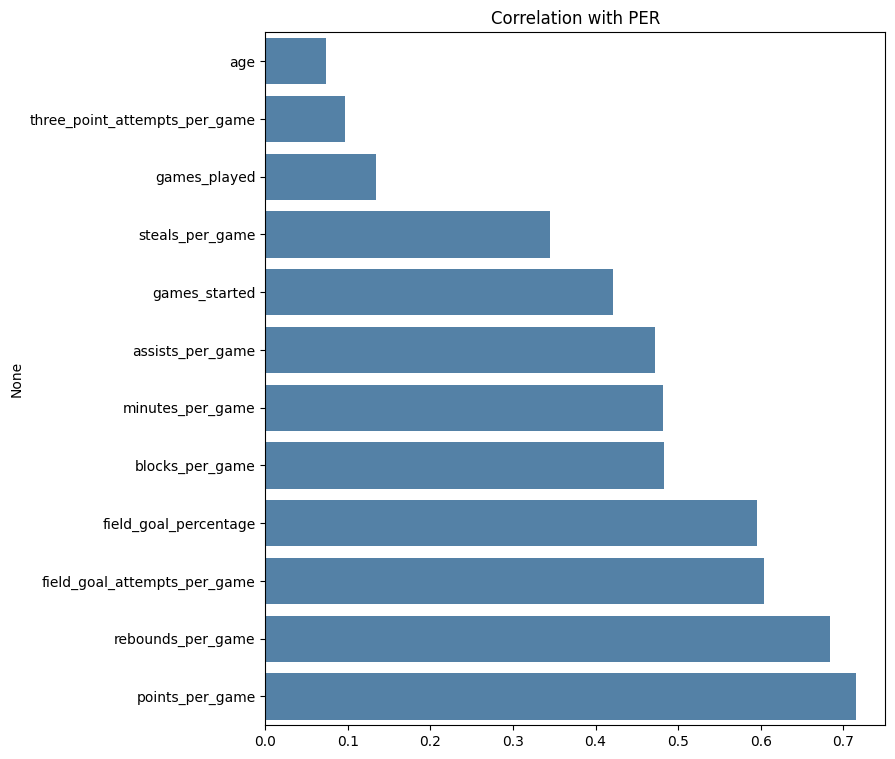

In [57]:
corr = reg_df[features].corrwith(reg_df[target]).sort_values()

plt.figure(figsize=(8, 9))
sns.barplot(x=corr.values, y=corr.index, color="steelblue")
plt.title("Correlation with PER")
plt.show()

In [58]:
X = reg_df[features]
y = reg_df[target]

split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(X, y, groups=reg_df.player_id))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

model = LinearRegression()
model.fit(X_train, y_train)

print("Train:", len(X_train), "| Test:", len(X_test))

Train: 1425 | Test: 378


In [59]:
def evaluate(X, y):
    pred = model.predict(X)
    mse = mean_squared_error(y, pred)
    return {"R2": r2_score(y, pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y, pred)}

display(pd.DataFrame({"Train": evaluate(X_train, y_train), "Test": evaluate(X_test, y_test)}).round(3))

,Train,Test
R2,0.923,0.926
MSE,1.537,1.691
RMSE,1.240,1.300
MAE,0.965,1.013


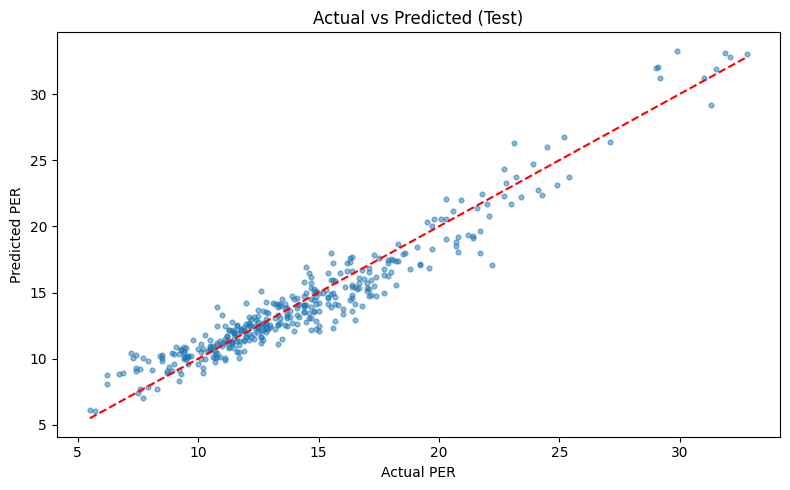

In [60]:
pred = model.predict(X_test)

plt.figure(figsize=(8, 5))

plt.scatter(y_test, pred, s=12, alpha=0.5)

lim = [y_test.min(), y_test.max()]
plt.plot(lim, lim, "r--")

plt.title("Actual vs Predicted (Test)")
plt.xlabel("Actual PER")
plt.ylabel("Predicted PER")

plt.tight_layout()
plt.show()

In [61]:
feat = ["age", "minutes_played", "played_efficiency_rating", "usage_percentage", "true_shooting_percentage", "assist_percentage", "total_rebound_percentage", "turnover_percentage", "points_per_game", "minutes_per_game"]
base = players[players.minutes_played >= 500][["player_id", "season_end"] + feat]


nxt = base[["player_id", "season_end", "played_efficiency_rating"]].assign(season_end=lambda d: d.season_end - 1).rename(columns={"played_efficiency_rating": "per_next"})
nxt_df = base.merge(nxt, on=["player_id", "season_end"]).dropna()
X_nxt, y_nxt, groups = nxt_df[feat], nxt_df.per_next, nxt_df.player_id

models = {
    "Ridge (regularized linear)": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 2, 20))),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, random_state=42),
}
cv = GroupKFold(n_splits=5)   
scores = {n: cross_val_score(m, X_nxt, y_nxt, cv=cv, groups=groups, scoring="r2").mean() for n, m in models.items()}
scores["Baseline (next PER = this PER)"] = r2_score(y_nxt, nxt_df.played_efficiency_rating)

px.bar(x=list(scores.values()), y=list(scores.keys()), orientation="h", text_auto=".2f",
       title="Predicting next-season PER: model comparison (R², 5-fold CV)").show()

<div dir="rtl" style="text-align: right;">

### ۵. پیشنهاد خرید بازیکن در پست Point Guard

**هدف:** باشگاه می‌خواهد برای فصل بعد یک Point Guard با توانایی بالا بخرد. معیار توانایی، حضور بازیکن در لیست جایزه Michael Jordan Trophy (رأی‌گیری MVP) است و بازیکنی که حضور بیشتری داشته، اولویت بالاتری دارد.

**روش کار:**
۱. از رأی‌گیری MVP فقط فصل‌های ۲۰۱۹-۲۰ تا ۲۰۲۳-۲۴ (`season_end` از ۲۰۲۰ تا ۲۰۲۴) را برمی‌داریم و تعداد فصل‌های حضور هر بازیکن را می‌شماریم.
۲. فقط بازیکنانی را نگه می‌داریم که در آخرین فصل (۲۰۲۳-۲۴) در پست PG ثبت شده‌اند.
۳. چون خرید برای فصل بعد است، دو شرط آمادگی می‌گذاریم: حداقل ۵۰ بازی در فصل ۲۰۲۳-۲۴ (دسترس‌پذیری) و `box_plus_minus ≥ 3` (سطح ستاره).
۴. بازیکنان را اول بر اساس تعداد حضور در لیست MVP و بعد بر اساس BPM مرتب می‌کنیم و ۳ نفر اول را پیشنهاد می‌دهیم.

</div>

,name,appearances,best_rank,mvp_points,age,games_played,points_per_game,assists_per_game,played_efficiency_rating,true_shooting_percentage,assist_percentage,turnover_percentage,box_plus_minus,value_over_replacement_player,win_shares_per_48_minutes
0,Luka Dončić,5,3,964.0,24.0,70,33.9,9.8,28.1,0.62,44.3,12.8,9.9,8.0,0.22
1,Stephen Curry,3,3,462.0,35.0,74,26.4,5.1,20.6,0.62,24.7,11.7,5.2,4.4,0.14
2,Shai Gilgeous-Alexander,2,2,686.0,25.0,75,30.1,6.2,29.3,0.64,29.8,8.4,9.0,7.1,0.28
3,Jalen Brunson,2,5,143.0,27.0,77,28.7,6.7,23.4,0.59,33.5,9.1,5.8,5.4,0.20
4,James Harden,2,3,368.0,34.0,72,16.6,8.5,18.6,0.61,33.6,16.0,4.1,3.8,0.16
5,Devin Booker,1,4,216.0,27.0,68,27.1,6.9,21.9,0.61,31.2,10.6,3.0,3.1,0.18


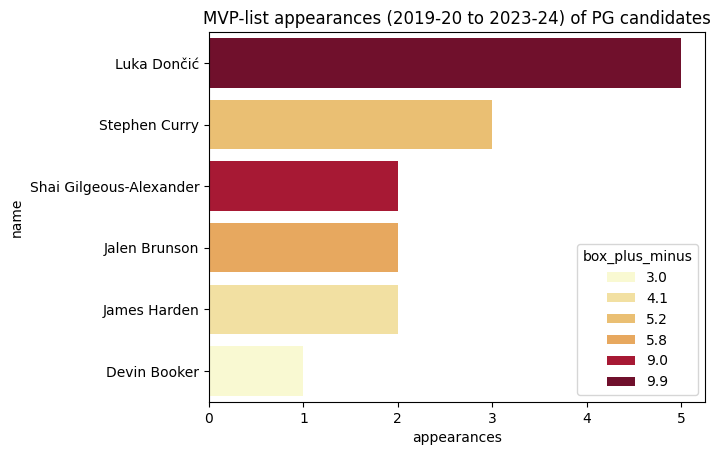

Final Recommendation: Luka Dončić, Stephen Curry, Shai Gilgeous-Alexander


In [62]:
m = mvp[mvp.season_end.between(2020, 2024)]
presence = m.groupby("player_id").agg(
    name=("full_name", "first"),
    appearances=("season_end", "nunique"),
    best_rank=("mvp_rank", "min"),
    mvp_points=("mvp_points", "sum")).reset_index()


last = players[players.season_end == 2024][["player_id", "position_name", "age", "games_played", "points_per_game", "assists_per_game",
                                            "played_efficiency_rating", "true_shooting_percentage", "assist_percentage", "turnover_percentage", "box_plus_minus", "value_over_replacement_player", "win_shares_per_48_minutes"]]
cand = presence.merge(last, on="player_id")
cand = cand[cand.position_name == "PG"]


ready = cand[(cand.games_played >= 50) & (cand.box_plus_minus >= 3)]
ready = ready.sort_values(["appearances", "box_plus_minus"], ascending=False).reset_index(drop=True)
display(ready.drop(columns=["player_id", "position_name"]).round(2))


sns.barplot(data=ready, x="appearances", y="name", hue="box_plus_minus", palette="YlOrRd", dodge=False)
plt.title("MVP-list appearances (2019-20 to 2023-24) of PG candidates")
plt.show()

top3 = ready.head(3)
print("Final Recommendation:", ", ".join(top3.name))

<div dir="rtl" style="text-align: right;">

### نتیجه‌گیری

از ۱۳ بازیکن PG حاضر در لیست MVP، شش نفر شرط آمادگی (حداقل ۵۰ بازی و BPM حداقل ۳) را داشتند. سه پیشنهاد نهایی به ترتیب اولویت:

۱. **Luka Dončić:** تنها PG حاضر در هر ۵ فصل لیست (رتبه ۳ در بهترین فصل). بالاترین BPM (۹٫۹) و VORP (۸٫۰)، ۲۴ ساله، با AST% برابر ۴۴٫۳ که نشان‌دهنده هوش بسکتبالی بالاست.
۲. **Stephen Curry:** با ۳ حضور، بیشترین حضور بعد از Luka را دارد. هنوز در سطح ستاره است (BPM ۵٫۲، TS% ۶۱٫۶، ۷۴ بازی). ریسک او سن بالاست (۳۶ سال در فصل بعد).
۳. **Shai Gilgeous-Alexander:** ۲ حضور پشت‌سرهم و صعودی (رتبه ۵ و سپس ۲). بالاترین WS/۴۸ (۰٫۲۷۵) و کمترین درصد توپ‌ازدست‌دادن (۸٫۴٪) را دارد و ۲۵ ساله است.

**چرا Chris Paul انتخاب نشد؟** او هم ۳ حضور دارد، اما در ۲۰۲۳-۲۴ فقط ۵۸ بازی کرده و BPM او ۱٫۰ است. با شرط `box_plus_minus ≥ 3` و هدف «شروع قدرتمند در فصل بعد» جزو کاندیدها نماند.

**محدودیت:** داده‌ای از حقوق و قرارداد بازیکنان در فایل نیست، پس توان مالی باشگاه بررسی نشده است.

</div>